# Evaluasi Verifikasi Realisasi Indikator RPJMN 2025-2029
Gemma 4 26B A4B vs Qwen3 30B A3B

## 1. Setup

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

import os
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv())
assert os.environ.get("GROQ_API_KEY"), "GROQ_API_KEY belum diisi di .env"
assert os.environ.get("BAGIAN_KE") in {"1", "2", "3"}, "BAGIAN_KE di .env harus 1, 2, atau 3"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

DATA_OUT = Path("../data/output")

# Nama pendek untuk tabel dan grafik
MODELS = {
    "gemma-4-26b-a4b-it":               "Gemma 4 26B A4B",
    "watsonx-qwen3-30b-a3b-instruct-2": "Qwen3 30B A3B",
}
ORDER = list(MODELS.values())
G, Q = ORDER

# Warna mengikuti model, tidak pernah dipakai untuk arti lain
COLORS = {G: "#2a78d6", Q: "#eb6834"}
# Skor judge 0-1-2 berurutan, jadi satu warna dari terang ke gelap
WARNA_SKOR = {0: "#86b6ef", 1: "#3987e5", 2: "#184f95"}
CMAP_BIRU = LinearSegmentedColormap.from_list("biru", ["#ffffff", "#cde2fb", "#2a78d6"])
ABU = "#c3c2b7"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (c - h, c + h)


def fmt_ci(k, n):
    # proporsi beserta pembilang/penyebut dan interval Wilson 95%
    lo, hi = wilson(k, n)
    return f"{k/n:.1%} ({k}/{n}) [{lo:.1%}-{hi:.1%}]" if n else "-"

## 2. Muat dan validasi

In [2]:
def latest(pattern):
    files = sorted(DATA_OUT.glob(pattern))
    if not files:
        raise FileNotFoundError(pattern)
    return files[-1]


frames, raws = [], []
for slug, nama in MODELS.items():
    f_det = latest(f"detail_{slug}_serper_*.csv")
    f_raw = DATA_OUT / f"raw_{slug}_serper.jsonl"
    d = pd.read_csv(f_det, encoding="utf-8-sig")
    d["model_nama"] = nama
    frames.append(d)

    with open(f_raw, encoding="utf-8") as fh:
        for line in fh:
            r = json.loads(line)
            raws.append({"model_nama": nama, "row_no": r["row_no"],
                         "tool_calls_log": r.get("tool_calls_log") or []})
    print(f"{nama:<16}: {f_det.name}  ({len(d)} baris)")

df = pd.concat(frames, ignore_index=True)
raw = pd.DataFrame(raws)

raw["n_hasil"] = raw["tool_calls_log"].apply(lambda L: sum(len(t.get("hasil") or []) for t in L))
df = df.merge(raw[["model_nama", "row_no", "n_hasil"]], on=["model_nama", "row_no"], how="left")
log_map = {(r["model_nama"], r["row_no"]): r["tool_calls_log"] for _, r in raw.iterrows()}

for c in ["gold", "pred", "benar", "domain_goid", "url_dari_search", "gold_suspect"]:
    df[c] = df[c].astype(bool)

wide = df.pivot(index="row_no", columns="model_nama", values=["pred", "benar"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.join(df.drop_duplicates("row_no").set_index("row_no")[["gold", "sektor", "kl", "sub_indikator"]])

cek = df.groupby("row_no")["gold"].nunique()
assert (cek == 1).all(), "Gold berbeda antar file model"
assert df.groupby("model_nama")["row_no"].nunique().eq(292).all(), "Jumlah baris tidak 292"
assert (df["benar"] == (df["gold"] == df["pred"])).all(), "Kolom benar tidak konsisten dengan gold dan pred"

n_true, n_false = int(wide["gold"].sum()), int((~wide["gold"]).sum())
print(f"\nStatus run : {df.groupby('model_nama')['status'].value_counts().to_dict()}")
print(f"Gold       : {n_true} TRUE, {n_false} FALSE dari {len(wide)} indikator")
print(f"Baseline 'selalu TRUE' sudah mencapai akurasi {n_true/len(wide):.1%}")

Gemma 4 26B A4B : detail_gemma-4-26b-a4b-it_serper_20260918_113127.csv  (292 baris)
Qwen3 30B A3B   : detail_watsonx-qwen3-30b-a3b-instruct-2_serper_20260917_150324.csv  (292 baris)

Status run : {('Gemma 4 26B A4B', 'OK'): 292, ('Qwen3 30B A3B', 'OK'): 292}
Gold       : 286 TRUE, 6 FALSE dari 292 indikator
Baseline 'selalu TRUE' sudah mencapai akurasi 97.9%


## 3. Metrik per kelas

In [3]:
def metrik(gold, pred):
    gold, pred = np.asarray(gold, bool), np.asarray(pred, bool)
    tp = int(( gold &  pred).sum()); fn = int(( gold & ~pred).sum())
    fp = int((~gold &  pred).sum()); tn = int((~gold & ~pred).sum())
    div = lambda a, b: a / b if b else np.nan
    rec_t, rec_f = div(tp, tp + fn), div(tn, tn + fp)
    pre_t, pre_f = div(tp, tp + fp), div(tn, tn + fn)
    f1 = lambda p, r: 0.0 if (pd.isna(p) or pd.isna(r) or p + r == 0) else 2 * p * r / (p + r)
    return {
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "Precision TRUE": pre_t, "Recall TRUE": rec_t, "F1 TRUE": f1(pre_t, rec_t),
        "Precision FALSE": pre_f, "Recall FALSE": rec_f, "F1 FALSE": f1(pre_f, rec_f),
        "Balanced accuracy": (rec_t + rec_f) / 2,
        "Macro F1": (f1(pre_t, rec_t) + f1(pre_f, rec_f)) / 2,
    }


hasil = {nama: metrik(d["gold"], d["pred"]) for nama, d in df.groupby("model_nama")}
hasil["Baseline: selalu TRUE"] = metrik(wide["gold"], np.ones(len(wide), bool))
tabel_metrik = pd.DataFrame(hasil)[ORDER + ["Baseline: selalu TRUE"]]

HITUNGAN = ["TP", "FN", "FP", "TN"]
tampil = pd.DataFrame({
    kol: [f"{int(v)}" if idx in HITUNGAN else ("-" if pd.isna(v) else f"{v:.1%}")
          for idx, v in tabel_metrik[kol].items()]
    for kol in tabel_metrik.columns
}, index=tabel_metrik.index)
tampil

,Gemma 4 26B A4B,Qwen3 30B A3B,Baseline: selalu TRUE
TP,270,172,286
FN,16,114,0
FP,5,5,6
TN,1,1,0
Precision TRUE,98.2%,97.2%,97.9%
Recall TRUE,94.4%,60.1%,100.0%
F1 TRUE,96.3%,74.3%,99.0%
Precision FALSE,5.9%,0.9%,-
Recall FALSE,16.7%,16.7%,0.0%
F1 FALSE,8.7%,1.7%,0.0%


In [4]:
# Interval Wilson 95% untuk keempat proporsi per kelas
rows = []
for nama in ORDER:
    m = hasil[nama]
    rows.append({
        "Model": nama,
        "Recall TRUE": fmt_ci(m["TP"], m["TP"] + m["FN"]),
        "Precision TRUE": fmt_ci(m["TP"], m["TP"] + m["FP"]),
        "Recall FALSE": fmt_ci(m["TN"], m["TN"] + m["FP"]),
        "Precision FALSE": fmt_ci(m["TN"], m["TN"] + m["FN"]),
    })
tabel_ci = pd.DataFrame(rows).set_index("Model").T
tabel_ci

Model,Gemma 4 26B A4B,Qwen3 30B A3B
Recall TRUE,94.4% (270/286) [91.1%-96.5%],60.1% (172/286) [54.4%-65.6%]
Precision TRUE,98.2% (270/275) [95.8%-99.2%],97.2% (172/177) [93.6%-98.8%]
Recall FALSE,16.7% (1/6) [3.0%-56.4%],16.7% (1/6) [3.0%-56.4%]
Precision FALSE,5.9% (1/17) [1.0%-27.0%],0.9% (1/115) [0.2%-4.8%]


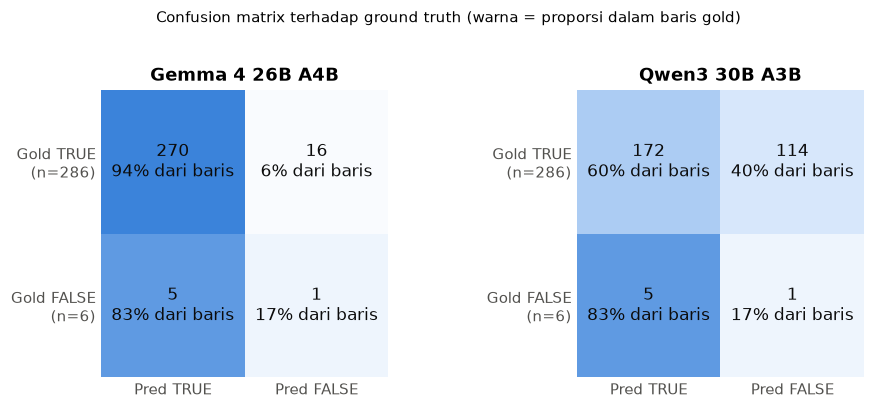

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, nama in zip(axes, ORDER):
    m = hasil[nama]
    cm = np.array([[m["TP"], m["FN"]], [m["FP"], m["TN"]]])
    # warna dihitung per baris, supaya baris gold FALSE (6 indikator) tetap terbaca
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=CMAP_BIRU, vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n{v/cm[i].sum():.0%} dari baris", ha="center", va="center",
                color="#0b0b0b", fontsize=11)
    ax.set_xticks([0, 1], ["Pred TRUE", "Pred FALSE"])
    ax.set_yticks([0, 1], [f"Gold TRUE\n(n={n_true})", f"Gold FALSE\n(n={n_false})"])
    ax.set_title(nama)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Confusion matrix terhadap ground truth (warna = proporsi dalam baris gold)", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

### 3.1 Sensitivitas tanpa baris `gold_suspect` (no=11)

In [6]:
print("Baris gold_suspect:", sorted(int(x) for x in df.loc[df["gold_suspect"], "row_no"].unique()))

tanpa11 = df[~df["gold_suspect"]]
sens = pd.DataFrame({nama: metrik(d["gold"], d["pred"]) for nama, d in tanpa11.groupby("model_nama")})[ORDER]

KOL_SENS = ["Recall TRUE", "Recall FALSE", "Balanced accuracy", "Macro F1"]
banding = pd.concat({"Gold asli": tabel_metrik.loc[KOL_SENS, ORDER],
                     "Tanpa no=11": sens.loc[KOL_SENS]}, axis=1).swaplevel(axis=1)[ORDER]
display(banding.style.format("{:.1%}"))
for nama in ORDER:
    print(f"{nama:<16}: recall FALSE {hasil[nama]['TN']}/{hasil[nama]['TN'] + hasil[nama]['FP']}"
          f" -> {int(sens.loc['TN', nama])}/{int(sens.loc['TN', nama] + sens.loc['FP', nama])}")

Baris gold_suspect: [11]


Gemma 4 26B A4B : recall FALSE 1/6 -> 1/5
Qwen3 30B A3B   : recall FALSE 1/6 -> 1/5


## 4. Evaluasi summary: groundedness dan relevansi (LLM-as-judge)

### 4.1 Input dan prompt

In [7]:
import os, time, shutil, datetime as dt

JUDGE_MODEL = "openai/gpt-oss-120b"
JUDGE_URL   = "https://api.groq.com/openai/v1"
JUDGE_LABEL = "GPT-OSS 120B (Groq)"

BAGIAN_KE, DARI = int(os.environ["BAGIAN_KE"]), 3

CKPT_DIR        = DATA_OUT / "judge_checkpoint"
F_JUDGE         = DATA_OUT / f"judge_groundedness_relevansi_gptoss120b_groq_bagian{BAGIAN_KE}.csv"
F_LOG           = CKPT_DIR / f"judge_run_log_bagian{BAGIAN_KE}.csv"
TOKEN_PER_MENIT = 6_000       # sengaja di bawah 8K
CKPT_DIR.mkdir(parents=True, exist_ok=True)

def sumber_teks(tool_calls_log, url, maks_lain=6):
    # pisahkan cuplikan sumber yang dikutip model dari cuplikan hasil pencarian lain
    dikutip, lain, lihat = [], [], set()
    for t in tool_calls_log:
        for h in (t.get("hasil") or []):
            u = h.get("url")
            if not u or u in lihat:
                continue
            lihat.add(u)
            s = f"- {h.get('judul') or ''}: {h.get('cuplikan') or ''}"
            (dikutip if (url and u == url) else lain).append(s)
    return "\n".join(dikutip), "\n".join(lain[:maks_lain])


def muat_baris():
    rows = []
    for _, r in df.iterrows():
        url = r["source_url_pred"] if pd.notna(r["source_url_pred"]) else None
        dik, lain = sumber_teks(log_map[(r["model_nama"], r["row_no"])], url)
        rows.append({"model_nama": r["model_nama"], "row_no": int(r["row_no"]),
                     "indikator": r["sub_indikator"],
                     "target": f"{r['target_2025']} {r['satuan']}",
                     "ringkasan": r["summary_pred"],
                     "sumber_dikutip": dik, "hasil_lain": lain})
    return rows


SYS_GROUND = '''Kamu penilai GROUNDEDNESS. Periksa apakah isi RINGKASAN didukung oleh teks sumber yang diberikan.
Jangan memakai pengetahuan di luar teks sumber. Perhatikan angka, nama kegiatan, lokasi, dan tahun.
Skor:
2 = semua klaim penting didukung SUMBER_DIKUTIP atau HASIL_LAIN
1 = sebagian klaim didukung, sebagian tidak ditemukan di teks
0 = klaim utama tidak ditemukan di teks sumber (diduga dikarang atau dari pengetahuan model sendiri)
Catatan: bila RINGKASAN menyatakan bukti tidak ditemukan, beri 2 jika teks sumber memang tidak memuat bukti itu.
Balas HANYA JSON: {"skor": 0, "alasan": "maks 10 kata"}'''

SYS_REL = '''Kamu penilai RELEVANSI. Nilai apakah teks membahas INDIKATOR yang ditanyakan.
Skor:
2 = membahas indikator yang sama (topik, objek, dan wilayah/sektor cocok)
1 = terkait tetapi bukan indikator yang persis sama (program induk, wilayah atau kelompok sasaran berbeda)
0 = tidak terkait
Nilai dua hal: "ringkasan" (isi RINGKASAN) dan "sumber" (isi SUMBER_DIKUTIP).
Balas HANYA JSON: {"ringkasan": 0, "sumber": 0, "alasan": "maks 10 kata"}'''

def prompt_ground(r):
    return (f"RINGKASAN: {r['ringkasan']}\n\n"
            f"SUMBER_DIKUTIP:\n{r['sumber_dikutip'] or '(tidak ada)'}\n\n"
            f"HASIL_LAIN:\n{r['hasil_lain'] or '(tidak ada)'}")

def prompt_rel(r):
    return (f"INDIKATOR: {r['indikator']} (target 2025: {r['target']})\n\n"
            f"RINGKASAN: {r['ringkasan']}\n\n"
            f"SUMBER_DIKUTIP:\n{r['sumber_dikutip'] or '(tidak ada)'}")

baris_judge = muat_baris()
# cuplikan sumber yang dikutip, dipakai lagi di 4.4 dan 6.4
df["teks_sumber_dikutip"] = pd.Series([r["sumber_dikutip"].replace("\n", " ") for r in baris_judge], index=df.index)
n_tanpa_sumber = sum(1 for r in baris_judge if not r["sumber_dikutip"])
terpanjang = max(len(SYS_GROUND) + len(prompt_ground(r)) for r in baris_judge)
print(f"Baris yang akan dinilai        : {len(baris_judge)} ({len(baris_judge) * 2} panggilan)")
print(f"Tanpa sumber yang dikutip      : {n_tanpa_sumber} (relevansi sumber dikosongkan)")
print(f"Prompt terpanjang              : {terpanjang} karakter")
print("\n--- Contoh prompt groundedness, baris pertama ---")
print(prompt_ground(baris_judge[0])[:900])

bagianmu = [r for r in baris_judge if r["row_no"] % DARI == BAGIAN_KE % DARI]
print(f"\nBagian {BAGIAN_KE} dari {DARI}: {len(bagianmu)} baris ({len(bagianmu) * 2} panggilan)")
print(pd.Series([r["row_no"] % DARI for r in baris_judge]).value_counts().sort_index())

Baris yang akan dinilai        : 584 (1168 panggilan)
Tanpa sumber yang dikutip      : 68 (relevansi sumber dikosongkan)
Prompt terpanjang              : 2724 karakter

--- Contoh prompt groundedness, baris pertama ---
RINGKASAN: Program berjalan, ditandai dengan adanya kegiatan verifikasi lapangan oleh tim verifikator STBM 5 Pilar tingkat nasional di berbagai daerah seperti Kota Malang dan Blitar pada Oktober 2025. Kegiatan ini merupakan bagian dari proses penilaian untuk mencapai status deklarasi 5 pilar STBM di tingkat kabupaten/kota.

SUMBER_DIKUTIP:
- Verifikator STBM 5 Pilar Kunjungi Kota Malang: Adapun lima STBM mencakup Stop Buang Air Besar Sembarangan (BABS), Cuci Tangan Pakai Sabun (CTPS), Pengolahan Air Minum dan Makanan Rumah Tangga ...

HASIL_LAIN:
- Deklarasi 5 Pilar STBM dan Penggalangan Komitmen Lintas Sektor: Adapun 5 Pilar STBM yang dimaksud adalah sebagai berikut: 1. Stop Buang Air Besar Sembarangan, kondisi ketika setiap individu dalam suatu ...
- Hay Sobat Healthie

In [8]:
from openai import OpenAI

c = OpenAI(base_url=JUDGE_URL, api_key=os.environ["GROQ_API_KEY"])
r = c.chat.completions.create(
    model=JUDGE_MODEL, temperature=0, max_completion_tokens=800,
    extra_body={"reasoning_effort": "low"},
    messages=[{"role": "system", "content": SYS_GROUND},
              {"role": "user", "content": prompt_ground(baris_judge[0])}])
print(r.choices[0].message.content)
print(r.usage)
perkiraan = r.usage.total_tokens * len(bagianmu) * 2
print(f"Perkiraan token bagianmu: {perkiraan:,} | sekitar {perkiraan/200_000:.1f} hari")

{"skor": 1, "alasan": "Tidak ada bukti tanggal dan Blitar"}
CompletionUsage(completion_tokens=139, prompt_tokens=707, total_tokens=846, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=None, audio_tokens=None, reasoning_tokens=109, rejected_prediction_tokens=None, text_tokens=None), prompt_tokens_details=None, queue_time=0.050776659, prompt_time=0.034052109, completion_time=0.294974964, total_time=0.329027073)
Perkiraan token bagianmu: 328,248 | sekitar 1.6 hari


### 4.2 Menjalankan judge

In [9]:
from openai import OpenAI, RateLimitError

JALANKAN_JUDGE = True
BATAS = int(os.environ.get("BATAS", "0")) or None    # BATAS di .env: 5 untuk tes, hapus atau 0 untuk run penuh

KOL_JUDGE = ["judge_groundedness", "judge_rel_ringkasan", "judge_rel_sumber",
             "alasan_groundedness", "alasan_relevansi"]


class JudgeTakTerhubung(Exception):
    pass

class KuotaHarianHabis(Exception):
    pass

def parse_json(txt):
    t = re.sub(r"```(?:json)?", "", txt or "").strip()
    m = re.search(r"\{.*\}", t, re.S)
    try:
        return json.loads(m.group(0)) if m else None
    except Exception:
        return None


def skor_valid(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool) and v in (0, 1, 2)


def panggil(client, system, user, kunci, coba=3):
    galat, token = None, 0
    for n in range(coba):
        try:
            resp = client.chat.completions.create(
                model=JUDGE_MODEL, temperature=0, timeout=180,
                max_completion_tokens=800,
                extra_body={"reasoning_effort": "low"},
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
        except RateLimitError as e:
            pesan = str(e).lower()
            try:
                tunggu = float(e.response.headers.get("retry-after", 0))
            except Exception:
                tunggu = 0
            if "per day" in pesan or "(tpd)" in pesan or "(rpd)" in pesan or tunggu > 120:
                raise KuotaHarianHabis(str(e))      # kuota harian habis -> stop
            galat = e
            time.sleep(max(20 * (n + 1), min(tunggu, 60)))   # limit per menit -> tunggu
            continue
        except Exception as e:
            galat = e
            continue
        galat = None
        token += resp.usage.total_tokens if resp.usage else 0
        j = parse_json(resp.choices[0].message.content)
        if j and all(skor_valid(j.get(k)) for k in kunci):
            return j, token
    if galat is not None:
        raise JudgeTakTerhubung(repr(galat))
    return None, token

def simpan_checkpoint(n_tulis, token_run, alasan):
    hari = str(dt.date.today())
    total = 0
    if F_JUDGE.exists():
        shutil.copy2(F_JUDGE, CKPT_DIR / f"{F_JUDGE.stem}_{hari}.csv")
        total = len(pd.read_csv(F_JUDGE, encoding="utf-8-sig")
                      .drop_duplicates(["model_nama", "row_no"]))
    pd.DataFrame([{"tanggal": hari, "jam": dt.datetime.now().strftime("%H:%M"),
                   "baris_ditulis": n_tulis, "token": token_run,
                   "total_baris_selesai": total, "alasan_stop": alasan}]
                 ).to_csv(F_LOG, mode="a", header=not F_LOG.exists(), index=False)
    print(f"\nCheckpoint: {total} baris selesai | sesi ini {n_tulis} baris, "
          f"{token_run} token | berhenti karena: {alasan}")
    
def jalankan(batas=None):
    client = OpenAI(base_url=JUDGE_URL, api_key=os.environ["GROQ_API_KEY"])

    sudah = set()
    if F_JUDGE.exists():
        s = pd.read_csv(F_JUDGE, encoding="utf-8-sig")
        s = s[s["judge_groundedness"].notna() & s["judge_rel_ringkasan"].notna()]   # baris yang gagal diulang
        sudah = set(zip(s["model_nama"], s["row_no"]))
    baris = [r for r in muat_baris() if (r["model_nama"], r["row_no"]) not in sudah]
    baris = [r for r in baris if r["row_no"] % DARI == BAGIAN_KE % DARI]            # hanya bagianmu
    baris.sort(key=lambda r: (r["row_no"], r["model_nama"]))                        # Gemma dan Qwen maju bergantian
    if batas:
        baris = baris[:batas]
    print(f"Bagian {BAGIAN_KE}/{DARI} | dinilai: {len(baris)} baris (sudah ada: {len(sudah)})")

    token_run, n_tulis, gagal_beruntun, alasan = 0, 0, 0, "semua baris selesai"
    try:
        for i, r in enumerate(baris, 1):
            ada_sumber = bool(r["sumber_dikutip"])
            try:
                g, t1 = panggil(client, SYS_GROUND, prompt_ground(r), ["skor"])
                v, t2 = panggil(client, SYS_REL, prompt_rel(r),
                                ["ringkasan"] + (["sumber"] if ada_sumber else []))
            except JudgeTakTerhubung as e:
                gagal_beruntun += 1
                if gagal_beruntun >= 3:
                    raise RuntimeError(f"Judge gagal 3x beruntun. Cek GROQ_API_KEY/koneksi. "
                                       f"Galat terakhir: {e}") from None
                continue
            gagal_beruntun = 0
            token_row = t1 + t2
            token_run += token_row
            out = {
                "model_nama": r["model_nama"], "row_no": r["row_no"],
                "judge_groundedness": int(g["skor"]) if g else None,
                "judge_rel_ringkasan": int(v["ringkasan"]) if v else None,
                "judge_rel_sumber": int(v["sumber"]) if (v and ada_sumber) else None,
                "alasan_groundedness": (g or {}).get("alasan", ""),
                "alasan_relevansi": (v or {}).get("alasan", ""),
            }
            pd.DataFrame([out]).to_csv(F_JUDGE, mode="a", header=not F_JUDGE.exists(),index=False, encoding="utf-8-sig")
            n_tulis += 1
            if i % 10 == 0 or i == len(baris):
                print(f"  {i}/{len(baris)} | token sesi ini: {token_run}")
            time.sleep(max(2, token_row / TOKEN_PER_MENIT * 60))   # jaga limit 8K token/menit
    except KuotaHarianHabis:
        alasan = "kuota harian API habis"
    except KeyboardInterrupt:
        alasan = "dihentikan manual"
    finally:
        simpan_checkpoint(n_tulis, token_run, alasan)
    return n_tulis

if JALANKAN_JUDGE:
    jalankan(BATAS)
elif F_JUDGE.exists():
    print(f"Memakai hasil judge yang sudah ada: {F_JUDGE.name}")
else:
    print(f"Belum ada {F_JUDGE.name}. Set JALANKAN_JUDGE = True untuk memulai.")

Bagian 2/3 | dinilai: 189 baris (sudah ada: 5)
  10/189 | token sesi ini: 13186
  20/189 | token sesi ini: 26523
  30/189 | token sesi ini: 39604
  40/189 | token sesi ini: 53314
  50/189 | token sesi ini: 65923
  60/189 | token sesi ini: 79303
  70/189 | token sesi ini: 92733
  80/189 | token sesi ini: 106256
  90/189 | token sesi ini: 119764
  100/189 | token sesi ini: 133537
  110/189 | token sesi ini: 146379
  120/189 | token sesi ini: 159556
  130/189 | token sesi ini: 172865
  140/189 | token sesi ini: 185572
  150/189 | token sesi ini: 199226

Checkpoint: 160 baris selesai | sesi ini 155 baris, 205648 token | berhenti karena: kuota harian API habis


In [ ]:
s = pd.read_csv(F_JUDGE, encoding="utf-8-sig").drop_duplicates(["model_nama", "row_no"])
print(f"Bagian {BAGIAN_KE}: {len(s)} baris selesai")
print("Skor kosong:", s[["judge_groundedness", "judge_rel_ringkasan"]].isna().sum().to_dict())

In [ ]:
GABUNG = False      # ganti True setelah ketiga CSV bagian ada di data/output

if GABUNG:
    bagian = sorted(DATA_OUT.glob("judge_groundedness_relevansi_gptoss120b_groq_bagian*.csv"))
    print([p.name for p in bagian])
    gab = (pd.concat([pd.read_csv(p, encoding="utf-8-sig") for p in bagian])
             .drop_duplicates(["model_nama", "row_no"], keep="last"))
    F_FINAL = DATA_OUT / "judge_groundedness_relevansi_gptoss120b_groq.csv"
    gab.to_csv(F_FINAL, index=False, encoding="utf-8-sig")
    print(len(gab), "dari", len(df), "baris")
    print(gab.groupby("model_nama").size())
    F_JUDGE = F_FINAL

### 4.3 Hasil

In [ ]:
if F_JUDGE.exists():
    jd = (pd.read_csv(F_JUDGE, encoding="utf-8-sig")
            .drop_duplicates(["model_nama", "row_no"], keep="last"))
    hj = df.merge(jd[["model_nama", "row_no"] + KOL_JUDGE].assign(ada_di_file=True),
                  on=["model_nama", "row_no"], how="left")
    hj["ada_di_file"] = hj["ada_di_file"].eq(True)
else:
    hj = df.copy()
    for c in KOL_JUDGE:
        hj[c] = np.nan
    hj["ada_di_file"] = False
assert len(hj) == len(df), "Penggabungan skor judge mengubah jumlah baris"
ADA_JUDGE = bool(hj["judge_groundedness"].notna().any())

def ringkas_judge(d):
    g, rr, rs = (d[c].dropna() for c in ["judge_groundedness", "judge_rel_ringkasan", "judge_rel_sumber"])
    porsi = lambda s, v: f"{(s == v).mean():.1%} ({int((s == v).sum())}/{len(s)})" if len(s) else "-"
    return {
        "Groundedness: baris dinilai": f"{len(g)} dari {len(d)}",
        "Groundedness rata-rata (0-2)": f"{g.mean():.2f}",
        "Groundedness = 2": porsi(g, 2),
        "Groundedness = 0": porsi(g, 0),
        "Relevansi ringkasan rata-rata (0-2)": f"{rr.mean():.2f}",
        "Relevansi ringkasan = 0": porsi(rr, 0),
        "Relevansi sumber: baris dinilai": f"{len(rs)} dari {len(d)}",
        "Relevansi sumber rata-rata (0-2)": f"{rs.mean():.2f}",
        "Relevansi sumber = 0": porsi(rs, 0),
    }

if ADA_JUDGE:
    tabel_judge = pd.DataFrame({nama: ringkas_judge(d) for nama, d in hj.groupby("model_nama")})[ORDER]
    display(tabel_judge)
    n_belum = int((~hj["ada_di_file"]).sum())
    n_kosong = int((hj["ada_di_file"] & hj["judge_groundedness"].isna()).sum())
    print(f"Baris yang belum dinilai (belum ada di file)       : {n_belum}"
          + ("  -> run belum penuh, angka di atas belum final" if n_belum else ""))
    print(f"Baris dinilai tetapi skor groundedness-nya kosong  : {n_kosong}")
else:
    tabel_judge = None
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

### 4.4 Contoh penilaian judge

In [ ]:
def contoh_judge(kol_skor, kol_alasan, judul, n=5, seed=42):
    d = hj[hj[kol_skor] == 0]
    print("=" * 110)
    print(f"{judul} = 0: {len(d)} baris, ditampilkan {min(n, len(d))}")
    print("=" * 110)
    for _, r in d.sample(min(n, len(d)), random_state=seed).iterrows():
        print(f"[{r['model_nama']}] no={r['row_no']} | pred={r['pred']} | {str(r['sub_indikator'])[:80]}")
        print(f"  Summary : {str(r['summary_pred'])[:260]}")
        print(f"  Sumber  : {str(r['teks_sumber_dikutip'])[:260] or '(tidak ada)'}")
        print(f"  Alasan  : {r[kol_alasan]}")
        print()

if ADA_JUDGE:
    contoh_judge("judge_groundedness", "alasan_groundedness", "Groundedness")
    contoh_judge("judge_rel_sumber", "alasan_relevansi", "Relevansi sumber")
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

## 5. Keputusan model

In [ ]:
def kriteria(nama):
    m = hasil[nama]
    d = hj[hj.model_nama == nama]
    tok = d[["in_tok", "out_tok"]].sum(axis=1)
    out = {
        "Recall TRUE": fmt_ci(m["TP"], m["TP"] + m["FN"]),
        "Precision TRUE": fmt_ci(m["TP"], m["TP"] + m["FP"]),
        "Recall FALSE": fmt_ci(m["TN"], m["TN"] + m["FP"]),
        "Balanced accuracy": f"{m['Balanced accuracy']:.1%}",
    }
    if ADA_JUDGE:
        g, rs = d["judge_groundedness"].dropna(), d["judge_rel_sumber"].dropna()
        out |= {
            "Groundedness rata-rata (0-2)": f"{g.mean():.2f}",
            "Groundedness = 0": f"{(g == 0).mean():.1%}",
            "Relevansi sumber = 0": f"{(rs == 0).mean():.1%}",
        }
    else:
        out |= {k: "menunggu judge" for k in
                ["Groundedness rata-rata (0-2)", "Groundedness = 0", "Relevansi sumber = 0"]}
    out |= {
        "Token rata-rata per indikator": f"{tok.mean():,.0f}",
        "Latensi median per indikator (dtk)": f"{d['latency_s'].median():.1f}",
        "Token per jawaban benar": f"{tok.sum() / d['benar'].sum():,.0f}",
    }
    return out


tabel_keputusan = pd.DataFrame({nama: kriteria(nama) for nama in ORDER})
tabel_keputusan

### 5.1 Human-in-the-loop

In [ ]:
ATURAN = {
    "Prediksi FALSE":                       ~hj["pred"],
    "URL bukti bukan dari hasil pencarian": ~hj["url_dari_search"],
    "source_type = tidak_ada":              hj["source_type"].eq("tidak_ada"),
    "Ada pencarian kosong":                 hj["n_search_gagal"] > 0,
    "judge_groundedness = 0":               hj["judge_groundedness"].eq(0),
    "judge_rel_sumber = 0":                 hj["judge_rel_sumber"].eq(0),
}
bendera = pd.DataFrame(ATURAN)
hj["perlu_tinjau"] = bendera.any(axis=1)
hj["perlu_tinjau_tanpa_judge"] = bendera.iloc[:, :4].any(axis=1)

per_aturan = bendera.groupby(hj["model_nama"]).sum().T[ORDER]
display(per_aturan)


def ringkas_tinjau(d, kol):
    t, fp = d[kol], d[~d.gold & d.pred]
    lolos = d[~t]
    return {
        "Baris ditinjau manusia": f"{int(t.sum())} dari {len(d)} ({t.mean():.0%})",
        "Kesalahan tertangkap": f"{int((t & ~d.benar).sum())} dari {int((~d.benar).sum())}",
        "  - false negative": f"{int((t & d.gold & ~d.pred).sum())} dari {int((d.gold & ~d.pred).sum())}",
        "  - false positive": f"{int(fp[kol].sum())} dari {len(fp)}",
        "Baris lolos tanpa tinjauan": len(lolos),
        "  - yang ternyata salah": int((~lolos.benar).sum()),
    }


kolom = [("Aturan tanpa judge", "perlu_tinjau_tanpa_judge")]
if ADA_JUDGE:
    kolom.append(("Semua aturan", "perlu_tinjau"))
tinjau = pd.DataFrame({(label, nama): ringkas_tinjau(hj[hj.model_nama == nama], kol)
                       for label, kol in kolom for nama in ORDER})
tinjau

## 6. EDA

### 6.1 Seperti apa data indikator yang dievaluasi?

In [ ]:
ind = df.drop_duplicates("row_no")
eda_sektor = (ind.groupby("sektor")
                 .agg(n=("row_no", "size"), jumlah_kl=("kl", "nunique"),
                      gold_false=("gold", lambda s: int((~s).sum())))
                 .sort_values("n", ascending=False))
eda_sektor["porsi"] = (eda_sektor["n"] / eda_sektor["n"].sum()).map("{:.0%}".format)
display(eda_sektor[["n", "porsi", "jumlah_kl", "gold_false"]])

kl = ind["kl"].value_counts()
print(f"Jumlah K/L: {kl.size}. Lima terbanyak: " + ", ".join(f"{k} ({v})" for k, v in kl.head(5).items()))
print(f"K/L dengan hanya 1-2 indikator: {(kl <= 2).sum()} dari {kl.size}")
print("\nBaris gold FALSE:")
display(ind.loc[~ind.gold, ["row_no", "sektor", "kl", "sub_indikator"]].set_index("row_no"))

**Insight.**

- Sosial (61) dan Industri (50) mencakup 38% dari 292 indikator, sedangkan Energi hanya 8.
- Ada 63 K/L dan 25 di antaranya hanya punya 1-2 indikator, jadi analisis per K/L tidak layak.
- Enam gold FALSE menumpuk di tiga sektor (Infrastruktur 3, Pangan 2, Sosial 1). Enam sektor lain tidak punya gold FALSE, sehingga recall FALSE tidak menguji model di sektor-sektor itu.

### 6.2 Di sektor mana model paling sering gagal mengenali program yang berjalan?

In [ ]:
# Hampir semua gold adalah TRUE, jadi yang dibandingkan per sektor adalah recall TRUE
t = df[df.gold]
sek = (t.groupby(["sektor", "model_nama"])["pred"].mean().unstack()[ORDER])
sek.insert(0, "n gold TRUE", t.drop_duplicates("row_no").groupby("sektor").size())
sek["selisih (G-Q)"] = sek[G] - sek[Q]
for nama in ORDER:
    sek[f"FN {nama}"] = t[t.model_nama == nama].groupby("sektor")["pred"].apply(lambda s: int((~s).sum()))
sek = sek.sort_values(Q)
display(sek.style.format({G: "{:.1%}", Q: "{:.1%}", "selisih (G-Q)": "{:+.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4.4))
y = np.arange(len(sek)); h = 0.38
for k, nama in enumerate(ORDER):
    b = ax.barh(y + (k - 0.5) * h, sek[nama] * 100, height=h, color=COLORS[nama],
                edgecolor="white", linewidth=1, label=nama)
    ax.bar_label(b, fmt="%.0f", padding=2, fontsize=8, color="#52514e")
ax.set_yticks(y, [f"{s} (n={n})" for s, n in zip(sek.index, sek["n gold TRUE"])]); ax.invert_yaxis()
ax.set_xlabel("Recall TRUE (%)"); ax.set_xlim(0, 108)
ax.set_title("Recall TRUE per sektor")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); plt.show()

terbanyak = sek[f"FN {G}"].idxmax()
print(f"False negative {G} di sektor {terbanyak}:")
for _, r in t[(t.model_nama == G) & (t.sektor == terbanyak) & ~t.pred].iterrows():
    print(f"  no={r['row_no']}: {str(r['sub_indikator'])[:120]}")

**Insight.**

- Kelemahan Qwen merata: recall TRUE di bawah 65% pada 7 dari 9 sektor, terendah Infrastruktur (42,9%, 20 FN dari 35). Masalahnya ada pada cara Qwen memutuskan, tidak pada topik indikatornya.
- Gemma hanya lemah di Industri (84,0%), yang menyumbang 8 dari 16 FN-nya. Empat dari delapan indikator itu terikat pada satu lokasi (KI Pulau Obi, KI Buli, Pulau Kalimantan).
- Energi (n=8) dibaca sebagai indikasi saja.

### 6.3 Di mana kedua model tidak sepakat, dan siapa yang benar saat itu?

In [ ]:
bg, bq = wide[f"benar_{G}"].astype(bool), wide[f"benar_{Q}"].astype(bool)
pg, pq = wide[f"pred_{G}"].astype(bool), wide[f"pred_{Q}"].astype(bool)

pasangan = pd.DataFrame(
    [[int((bg & bq).sum()),  int((bg & ~bq).sum())],
     [int((~bg & bq).sum()), int((~bg & ~bq).sum())]],
    index=[f"{G} benar", f"{G} salah"], columns=[f"{Q} benar", f"{Q} salah"])
display(pasangan)

arah = pd.crosstab(pg.map({True: "TRUE", False: "FALSE"}).rename(f"pred {G}"),
                   pq.map({True: "TRUE", False: "FALSE"}).rename(f"pred {Q}")).reindex(
                   index=["TRUE", "FALSE"], columns=["TRUE", "FALSE"], fill_value=0)
display(arah)

sepakat = pg == pq
gold = wide["gold"].astype(bool)
print(f"Sepakat : {int(sepakat.sum())} baris, {int((pg[sepakat] == gold[sepakat]).sum())} di antaranya benar "
      f"({(pg[sepakat] == gold[sepakat]).mean():.1%})")
print(f"Berbeda : {int((~sepakat).sum())} baris, {G} benar {int(bg[~sepakat].sum())}, {Q} benar {int(bq[~sepakat].sum())}")
print(f"          gold pada baris berbeda: TRUE = {int(gold[~sepakat].sum())}, FALSE = {int((~gold[~sepakat]).sum())}")
sama_true = sepakat & pg
print(f"Keduanya menjawab TRUE : {int(sama_true.sum())} baris, {int(gold[sama_true].sum())} di antaranya gold TRUE")

**Insight.**

- Ketidaksepakatan nyaris satu arah: dari 108 baris berbeda, 103 berbentuk Gemma TRUE dan Qwen FALSE, dan semuanya gold TRUE. Gemma unggul karena ambang Qwen jauh lebih ketat.
- Kesepakatan dua model tidak menangkap false positive: kelima FP ada di 172 baris yang dijawab TRUE oleh keduanya.
- Dua belas baris dijawab FALSE oleh keduanya: satu gold FALSE yang benar (no=44) dan 11 FN bersama, kandidat pertama untuk dicek ulang.

### 6.4 Mengapa 5 dari 6 indikator gold FALSE dijawab TRUE oleh kedua model?

In [ ]:
gold_file = pd.read_csv(DATA_OUT.parent / "raw" / "gold_standard_sample.csv", encoding="utf-8-sig")
print("Tanggal gold dibuat :", sorted(gold_file["created_at"].astype(str).str[:10].unique()))
print("Tanggal run model   :", df.groupby("model_nama")["timestamp"].min().str[:10].to_dict())

no_false = wide.index[~wide["gold"]]
d = df[df.row_no.isin(no_false)].sort_values(["row_no", "model_nama"])

ringkas_fp = d.pivot(index="row_no", columns="model_nama", values=["pred", "source_type", "evidence_year", "domain"])
ringkas_fp = ringkas_fp.swaplevel(axis=1)[ORDER]
ringkas_fp.insert(0, "gold_suspect", d.drop_duplicates("row_no").set_index("row_no")["gold_suspect"])
display(ringkas_fp)

for no, grp in d.groupby("row_no"):
    r0 = grp.iloc[0]
    print("=" * 110)
    print(f"no={no} | {r0['sektor']} | {r0['kl']} | {str(r0['sub_indikator'])[:90]}")
    print(f"  Gold FALSE : {str(r0['summary_gold'])[:330]}")
    for _, r in grp.iterrows():
        print(f"  {r['model_nama']} | pred={r['pred']}")
        print(f"      Summary  : {str(r['summary_pred'])[:330]}")
        print(f"      URL      : {r['source_url_pred'] if pd.notna(r['source_url_pred']) else '(tidak ada)'}")
        print(f"      Cuplikan : {str(r['teks_sumber_dikutip'])[:260] or '(tidak ada)'}")

**Insight.** Kedua model salah pada 5 baris yang sama, tetapi penyebabnya berbeda:

- **Gold tertinggal (no=11, no=173).** Gold dibuat 10 Desember 2025, model dijalankan September 2026 dan menemukan LKj 2025 yang terbit setelahnya. Di dua baris ini kemungkinan besar model yang benar.
- **Kegiatan terkait dianggap bukti (no=12, no=186, dan Qwen pada no=171).** Contohnya Rakornas Kehati 2025 dipakai sebagai bukti fasilitasi unit pengelola taman kehati, padahal prompt menggolongkan rapat sebagai FALSE.
- **Dokumen dari tahun yang salah (Gemma pada no=171).** Laporan Kinerja Triwulan II TA 2026 dicatat sebagai bukti 2025.
- Satu-satunya baris yang dijawab benar (no=44) adalah baris yang punya bukti positif bahwa program masih tahap perencanaan. Model tidak bisa membuktikan ketiadaan lewat pencarian.

### 6.5 Mengapa Qwen punya 114 false negative, sedangkan Gemma hanya 16?

In [ ]:
# Tiap false negative (gold TRUE, pred FALSE) dipilah dengan aturan berurutan: aturan pertama yang cocok dipakai
POLA_RENCANA = r"renstra|perencanaan|rencana|target|\brkp\b|rpjmn|dokumen strategis"

def kategori_fn(r):
    if r["n_hasil"] == 0:
        return "A. Tidak ada hasil pencarian sama sekali"
    if r["source_type"] == "tidak_ada" and r["n_search_gagal"] > 0:
        return "B. Ada pencarian kosong, bukti tidak ditemukan"
    if r["source_type"] == "tidak_ada":
        return "C. Hasil ada, tidak ada yang dianggap bukti"
    if re.search(POLA_RENCANA, str(r["summary_pred"]).lower()):
        return "D. Bukti dianggap hanya perencanaan/target"
    return "E. Bukti ditemukan, dinilai belum cukup"

KELOMPOK = {"A": "Retrieval", "B": "Retrieval", "C": "Relevansi", "D": "Penalaran", "E": "Penalaran"}

fn = df[df.gold & ~df.pred].copy()
fn["kategori"] = fn.apply(kategori_fn, axis=1)
fn["kelompok"] = fn["kategori"].str[0].map(KELOMPOK)

tax = pd.crosstab(fn["kategori"], fn["model_nama"]).reindex(columns=ORDER, fill_value=0)
kel = pd.crosstab(fn["kelompok"], fn["model_nama"]).reindex(["Retrieval", "Relevansi", "Penalaran"]).reindex(
    columns=ORDER, fill_value=0)
display(tax)
display((kel.astype(str) + " (" + (kel / kel.sum()).map("{:.0%}".format) + ")"))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(tax)); h = 0.38
for k, nama in enumerate(ORDER):
    b = ax.barh(y + (k - 0.5) * h, tax[nama], height=h, color=COLORS[nama],
                edgecolor="white", linewidth=1, label=nama)
    ax.bar_label(b, padding=2, fontsize=8, color="#52514e")
ax.set_yticks(y, tax.index); ax.invert_yaxis()
ax.set_xlabel("Jumlah false negative"); ax.set_title("False negative menurut penyebab")
ax.set_xlim(0, tax.to_numpy().max() * 1.1)
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Cek silang: apakah URL bukti yang dipakai model lain (yang menjawab benar) sebenarnya ikut muncul
# di hasil pencarian model ini? Bila ya, model ini sudah melihat bukti yang sama tetapi menolaknya.
url_terlihat = {k: {h.get("url") for t in L for h in (t.get("hasil") or [])} for k, L in log_map.items()}
lain = df.set_index(["model_nama", "row_no"])
for nama in ORDER:
    m_lain = Q if nama == G else G
    terlihat = []
    for _, r in fn[fn.model_nama == nama].iterrows():
        o = lain.loc[(m_lain, r["row_no"])]
        if o["pred"] and o["benar"] and o["url_dari_search"]:
            terlihat.append(o["source_url_pred"] in url_terlihat[(nama, r["row_no"])])
    print(f"{nama:<16}: pada {sum(terlihat)} dari {len(terlihat)} FN yang bisa dibandingkan, URL bukti {m_lain} "
          f"muncul di hasil pencariannya sendiri")

fn_g, fn_q = set(fn.loc[fn.model_nama == G, "row_no"]), set(fn.loc[fn.model_nama == Q, "row_no"])
print(f"\nFN bersama (kedua model menjawab FALSE pada gold TRUE): {len(fn_g & fn_q)} indikator; "
      f"hanya {G}: {len(fn_g - fn_q)}; hanya {Q}: {len(fn_q - fn_g)}")

for _, r in fn[fn.kategori.str.startswith("A")].iterrows():
    print(f"Kategori A | {r['model_nama']} | no={r['row_no']} | {r['n_search']} pencarian | {str(r['summary_pred'])[:330]}")

# Dua contoh kelompok penalaran pada Qwen, berdampingan dengan jawaban Gemma untuk indikator yang sama
for no in [7, 93]:
    r = fn[(fn.model_nama == Q) & (fn.row_no == no)]
    if r.empty:
        continue
    r, o = r.iloc[0], lain.loc[(G, no)]
    print("-" * 110)
    print(f"no={no} | {r['kategori']} | {str(r['sub_indikator'])[:80]}")
    print(f"  {Q} (FALSE): {str(r['summary_pred'])[:300]}")
    print(f"  {G} ({str(o['pred']).upper()}): {str(o['summary_pred'])[:300]}")

**Insight.**

- Separuh FN Qwen (56 dari 114, 49%) adalah bukti yang sudah ditemukan lalu ditolak: dianggap sekadar perencanaan atau target (38) atau dinilai belum cukup (18). Pada 31 dari 100 FN yang bisa dibandingkan, URL bukti Gemma muncul di hasil pencarian Qwen sendiri.
- Seperempat (30) berakar pada pencarian yang kosong, dan seperempat lagi (28) punya hasil tetapi tidak ada yang dikenali sebagai bukti.
- Dari 16 FN Gemma, 11 juga FN pada Qwen. Kasus no=157 bukan kesalahan model: kolom `keywords` di data input berisi "ekspor Sumatera" untuk indikator olahraga.

### 6.6 Bagaimana model memakai pencarian, dan apakah pencarian kosong berkaitan dengan salah jawab?

In [ ]:
# Pencarian "kosong" = tidak mengembalikan satu pun hasil.
# Pencarian "ber-site:" = dibatasi ke satu domain, lewat parameter `situs` atau operator site: di kueri.
calls = []
for (nama, row_no), L in log_map.items():
    for urutan, t in enumerate(L, 1):
        q = t.get("query") or ""
        calls.append({"model_nama": nama, "row_no": row_no, "urutan": urutan,
                      "situs": t.get("situs") or "".join(re.findall(r"site:(\S+)", q.lower())[:1]),
                      "pakai_site": bool(t.get("situs")) or ("site:" in q.lower()),
                      "n_hasil": len(t.get("hasil") or [])})
calls = pd.DataFrame(calls)
calls["kosong"] = calls["n_hasil"] == 0

cari = pd.DataFrame({
    nama: {
        "Total pencarian": len(c),
        "Rata-rata pencarian per indikator": f"{len(c) / 292:.2f}",
        "Indikator dengan 3 pencarian": int((c.groupby("row_no").size() == 3).sum()),
        "Pencarian ber-site:": f"{c['pakai_site'].sum()} ({c['pakai_site'].mean():.1%})",
        "  - pada pencarian pertama": f"{c.loc[c.urutan == 1, 'pakai_site'].sum()} dari {(c.urutan == 1).sum()}",
        "  - pada pencarian ke-2 dan seterusnya": f"{c.loc[c.urutan > 1, 'pakai_site'].sum()} dari {(c.urutan > 1).sum()}",
        "Pencarian kosong": f"{c['kosong'].sum()} ({c['kosong'].mean():.1%})",
        "Kosong saat ber-site:": f"{c.loc[c.pakai_site, 'kosong'].sum()} ({c.loc[c.pakai_site, 'kosong'].mean():.1%})",
        "Kosong saat tanpa site:": f"{c.loc[~c.pakai_site, 'kosong'].sum()} ({c.loc[~c.pakai_site, 'kosong'].mean():.1%})",
    } for nama, c in calls.groupby("model_nama")
})[ORDER]
display(cari)

# Hubungan dengan hasil akhir, hanya pada indikator gold TRUE
df["ada_gagal"] = df["n_search_gagal"] > 0
t = (df[df.gold].groupby(["model_nama", "ada_gagal"])["pred"].agg(["size", "sum", "mean"])
       .rename(columns={"size": "n gold TRUE", "sum": "dijawab TRUE", "mean": "recall TRUE"}))
t["recall TRUE"] = t["recall TRUE"].map("{:.1%}".format)
t.index = t.index.set_names(["Model", "Ada pencarian kosong?"])
display(t)

print("Domain `situs` yang paling sering mengembalikan 0 hasil:")
for nama in ORDER:
    top = calls[(calls.model_nama == nama) & calls.kosong & calls.situs.ne("")]["situs"].value_counts().head(6)
    print(f"  {nama:<16}: " + (", ".join(f"{k} ({v})" for k, v in top.items()) or "-"))

**Insight.**

- Qwen selalu memakai 3 pencarian. Gemma rata-rata 2,07 dan berhenti begitu bukti dirasa cukup.
- Qwen membatasi domain pada 576 dari 584 pencarian lanjutan, Gemma pada 138 dari 313.
- Semua pencarian kosong berasal dari `site:`, dengan tingkat kosong yang sama (sekitar 15%). Qwen hanya memakainya empat kali lebih sering: 90 pencarian kosong berbanding 21.
- Bila ada pencarian kosong, recall TRUE turun dari 96,2% ke 71,4% (Gemma) dan dari 69,7% ke 27,7% (Qwen).

### 6.7 Sumber apa yang dikutip model sebagai bukti?

In [ ]:
df["url_ada"] = df["source_url_pred"].fillna("").astype(str).str.strip().ne("")

def ringkas_bukti(d):
    ada = d[d["url_ada"]]
    karang = ~ada["url_dari_search"]
    return {
        "Baris dengan URL bukti": f"{len(ada)} dari {len(d)}",
        "URL tidak ada di hasil pencarian (karangan)": f"{int(karang.sum())} ({karang.mean():.1%})",
        "  - saat pred TRUE": int((karang & ada.pred).sum()),
        "  - saat pred FALSE": int((karang & ~ada.pred).sum()),
        "Domain .go.id (dari baris ber-URL)": f"{ada['domain_goid'].mean():.1%}",
        "Bukti bertahun 2025": f"{d['evidence_year'].astype(str).str[:4].eq('2025').mean():.1%}",
        "source_type = tidak_ada": int(d["source_type"].eq("tidak_ada").sum()),
    }

display(pd.DataFrame({nama: ringkas_bukti(d) for nama, d in df.groupby("model_nama")})[ORDER])

st_order = ["lkj", "siaran_pers", "bappenas", "bps_setkab", "renstra", "media", "tidak_ada"]
st = pd.crosstab(df["source_type"], df["model_nama"]).reindex(st_order).fillna(0).astype(int)[ORDER]
true_st = (df[df.pred].groupby(["source_type", "model_nama"]).size().unstack()
             .reindex(index=st_order, columns=ORDER).fillna(0).astype(int))
display(pd.concat({"jumlah baris": st, "dijawab TRUE": true_st, "dijawab FALSE": st - true_st}, axis=1))

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(st)); w = 0.38
for k, nama in enumerate(ORDER):
    b = ax.bar(x + (k - 0.5) * w, st[nama], width=w, color=COLORS[nama],
               edgecolor="white", linewidth=1, label=nama)
    ax.bar_label(b, fontsize=8, padding=1, color="#52514e")
ax.set_xticks(x, st.index); ax.set_ylabel("Jumlah indikator")
ax.set_title("Jenis sumber bukti yang dikutip model")
ax.grid(axis="x", visible=False); ax.legend()
plt.tight_layout(); plt.show()

print("Lima domain yang paling sering dikutip:")
for nama in ORDER:
    top = df.loc[(df.model_nama == nama) & df.url_ada, "domain"].value_counts().head(5)
    print(f"  {nama:<16}: " + ", ".join(f"{k} ({v})" for k, v in top.items()))

**Insight.**

- Siaran pers dan LKj mencakup 74% bukti Gemma dan 59% bukti Qwen.
- Qwen menemukan dokumen resmi tetapi menolak isinya: 22 dari 84 baris ber-LKj tetap dijawab FALSE, sedangkan semua 78 baris ber-LKj Gemma dijawab TRUE.
- Qwen berakhir tanpa sumber pada 59 baris (Gemma 10), semuanya dijawab FALSE.
- Gemma lebih permisif: 40 dari 44 baris bersumber media dijawab TRUE, dan facebook.com serta instagram.com masuk lima domain teratasnya.
- URL karangan hampir hanya muncul pada jawaban FALSE: 38 dari 39 pada Qwen.

### 6.8 Apakah `confidence` yang dilaporkan model bisa dipakai memilah jawaban yang salah?

In [ ]:
conf = (df.groupby(["model_nama", "benar"])["confidence"]
          .agg(["size", "mean", "median", "min", "max"]).round(1))
conf.index = conf.index.set_names(["Model", "Benar?"])
display(conf)

print("Nilai confidence yang muncul:")
for nama in ORDER:
    vc = df.loc[df.model_nama == nama, "confidence"].value_counts().sort_index()
    print(f"  {nama:<16}: " + ", ".join(f"{k}->{v}" for k, v in vc.items()))

# Kalau ambang confidence dipakai sebagai saringan: berapa kesalahan yang tertangkap?
print("\nBila baris dengan confidence < 90 dikirim ke peninjau:")
for nama in ORDER:
    d = df[df.model_nama == nama]
    rendah = d["confidence"] < 90
    print(f"  {nama:<16}: {int(rendah.sum())} baris ditinjau, memuat {int((rendah & ~d.benar).sum())} "
          f"dari {int((~d.benar).sum())} kesalahan")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
nilai = sorted(df["confidence"].unique())
x = np.arange(len(nilai)); w = 0.4
for ax, nama in zip(axes, ORDER):
    d = df[df.model_nama == nama]
    n_benar = d[d.benar]["confidence"].value_counts().reindex(nilai, fill_value=0)
    n_salah = d[~d.benar]["confidence"].value_counts().reindex(nilai, fill_value=0)
    ax.bar(x - w / 2, n_benar, width=w, color=COLORS[nama], edgecolor="white", linewidth=1, label="Benar")
    ax.bar(x + w / 2, n_salah, width=w, color=ABU, edgecolor="white", linewidth=1, label="Salah")
    ax.set_xticks(x, nilai); ax.set_xlabel("Confidence"); ax.set_title(nama)
    ax.grid(axis="x", visible=False); ax.legend()
axes[0].set_ylabel("Jumlah indikator")
fig.suptitle("Sebaran confidence: jawaban benar vs salah", y=1.03, fontsize=10)
plt.tight_layout(); plt.show()

**Insight.** `confidence` tidak bisa dipakai memilah jawaban yang salah.

- Nilainya menumpuk di 90 (178 dari 292 pada Gemma, 251 dari 292 pada Qwen), dan median untuk jawaban benar maupun salah sama-sama 90.
- Meninjau semua baris dengan confidence di bawah 90 hanya menemukan 10 dari 21 kesalahan Gemma dan 9 dari 119 kesalahan Qwen.

### 6.9 Berapa biaya token dan waktu tiap model?

In [ ]:
def ringkas_biaya(d):
    tok = d["in_tok"] + d["out_tok"]
    return {
        "Token input rata-rata": f"{d['in_tok'].mean():,.0f}",
        "Token output rata-rata": f"{d['out_tok'].mean():,.0f}",
        "Token total rata-rata per indikator": f"{tok.mean():,.0f}",
        "Token total seluruh run": f"{tok.sum():,.0f}",
        "Pencarian rata-rata per indikator": f"{d['n_search'].mean():.2f}",
        "Latensi rata-rata (dtk)": f"{d['latency_s'].mean():.1f}",
        "Latensi median (dtk)": f"{d['latency_s'].median():.1f}",
        "Latensi total (menit)": f"{d['latency_s'].sum() / 60:.1f}",
        "Jawaban benar": int(d["benar"].sum()),
        "Token per jawaban benar": f"{tok.sum() / d['benar'].sum():,.0f}",
    }

biaya = pd.DataFrame({nama: ringkas_biaya(d) for nama, d in df.groupby("model_nama")})[ORDER]
display(biaya)

tok = (df["in_tok"] + df["out_tok"]).groupby(df["model_nama"]).sum()
print(f"Token total {G} = {tok[G] / tok[Q]:.0%} dari {Q}")
print("Token input rata-rata menurut jumlah pencarian:")
per_cari = df.groupby(["n_search", "model_nama"])["in_tok"].agg(["size", "mean"]).unstack()
per_cari = per_cari.swaplevel(axis=1)[ORDER].rename(columns={"size": "n", "mean": "token input"})
display(per_cari.map(lambda v: "-" if pd.isna(v) else f"{v:,.0f}"))

**Insight.**

- Gemma memakai 58% token Qwen (4.531 berbanding 7.794 per indikator) dan lebih cepat (median 6,3 berbanding 9,7 detik).
- Pendorong utamanya jumlah pencarian: token input Gemma naik sekitar 2.000 per pencarian tambahan, dan Qwen selalu mencari 3 kali.
- Per jawaban benar, Qwen menghabiskan sekitar 2,7 kali token Gemma (13.155 berbanding 4.882).

### 6.10 Bagaimana sebaran skor groundedness tiap model?

In [ ]:
if ADA_JUDGE:
    hitung = (hj.groupby("model_nama")["judge_groundedness"].value_counts()
                .unstack().reindex(index=ORDER, columns=[0, 1, 2]).fillna(0).astype(int))
    dist = hitung.div(hitung.sum(axis=1), axis=0)
    display((hitung.astype(str) + " (" + dist.map("{:.1%}".format) + ")").rename_axis(columns="Skor groundedness"))

    fig, ax = plt.subplots(figsize=(8, 2.6))
    kiri = np.zeros(len(ORDER))
    for s in [0, 1, 2]:
        b = ax.barh(ORDER, dist[s] * 100, left=kiri, color=WARNA_SKOR[s], edgecolor="white", linewidth=2,
                    height=0.55, label=f"Skor {s}")
        ax.bar_label(b, labels=[f"{v:.0f}%" if v >= 6 else "" for v in dist[s] * 100], label_type="center",
                     color="#0b0b0b" if s == 0 else "white", fontsize=9)
        kiri += dist[s].values * 100
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Proporsi indikator (%)")
    ax.set_title("Sebaran skor groundedness (judge Llama 3.1 8B)")
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.42))
    plt.tight_layout(); plt.show()
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

**Insight.**

- Skor 0 jauh lebih banyak pada Qwen: 51,9% (150 dari 289) berbanding 29,0% pada Gemma (82 dari 283). Skor 1 hampir tidak dipakai (3,5% dan 3,9%), jadi judge praktis hanya memberi 0 atau 2.
- Selisih itu terutama berasal dari jawaban FALSE. Rata-rata groundedness jawaban FALSE yang salah hanya 0,40 (Qwen) dan 0,69 (Gemma), dan Qwen punya 115 jawaban FALSE sedangkan Gemma 17. Pada jawaban TRUE yang benar keduanya berdekatan: 1,42 (Gemma) dan 1,28 (Qwen).
- **Angka skor 0 kemungkinan terlalu tinggi.** Di contoh 4.4, dua dari lima alasan groundedness = 0 berbunyi "maks 1 kalimat", yaitu teks contoh di prompt yang disalin mentah oleh judge, dan contoh itu memuat skor 0. Pada no=53 judge menulis tahun 2025 tidak disebut, padahal cuplikannya memuat "Tahun 2025 dengan realisasi 3,78". Karena itu proporsi skor 0 tidak bisa dibaca sebagai "sekian persen summary dikarang".

### 6.11 Apakah jawaban yang benar punya summary yang lebih berdasar dan lebih relevan?

In [ ]:
if ADA_JUDGE:
    KOL = ["judge_groundedness", "judge_rel_ringkasan", "judge_rel_sumber"]
    t = hj.groupby(["model_nama", "benar"])[KOL].mean().round(2)
    t.insert(0, "n", hj.groupby(["model_nama", "benar"]).size())
    t.index = t.index.set_names(["Model", "Benar?"])
    display(t)

    # Dipecah menurut label prediksi: summary jawaban FALSE biasanya berbunyi "bukti tidak ditemukan"
    p = hj.groupby(["model_nama", "pred", "benar"])[KOL].mean().round(2)
    p.insert(0, "n", hj.groupby(["model_nama", "pred", "benar"]).size())
    p.index = p.index.set_names(["Model", "Pred", "Benar?"])
    display(p)
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

**Insight.**

- Jawaban benar mendapat skor lebih tinggi di semua dimensi, tetapi sebagian besar selisihnya adalah artefak judge: **semua jawaban FALSE mendapat relevansi ringkasan 0,00**, termasuk yang benar (no=44). Summary berbunyi "bukti tidak ditemukan" dinilai tidak relevan, padahal tetap membahas indikator yang ditanyakan. Jadi skor ini memisahkan jawaban TRUE dari FALSE, belum tentu benar dari salah.
- Perbandingan yang wajar adalah di antara jawaban TRUE. Di sana lima false positive punya relevansi lebih rendah daripada jawaban TRUE yang benar: relevansi sumber 0,80 berbanding 1,61 (Gemma) dan 1,00 berbanding 1,65 (Qwen). Groundedness tidak membedakan keduanya (1,50 berbanding 1,42, dan 1,20 berbanding 1,28).
- Ini sejalan dengan 5.1: aturan judge menangkap 3 dari 5 false positive pada tiap model, dari sebelumnya 0 dan 1. Harganya, baris yang perlu ditinjau naik dari 36 menjadi 126 (Gemma) dan dari 135 menjadi 197 (Qwen).

### 6.12 Sektor mana yang summary-nya paling kurang berdasar?

In [ ]:
if ADA_JUDGE:
    per_sektor = hj.pivot_table(index="sektor", columns="model_nama",
                                values="judge_groundedness", aggfunc="mean")[ORDER]
    nol = (hj.assign(nol=hj["judge_groundedness"].eq(0))
             .pivot_table(index="sektor", columns="model_nama", values="nol", aggfunc="sum")[ORDER].astype(int))
    out = pd.concat({"rata-rata groundedness": per_sektor.round(2), "jumlah skor 0": nol}, axis=1)
    out.insert(0, "n", hj.drop_duplicates("row_no").groupby("sektor").size())
    display(out.sort_values(("rata-rata groundedness", Q)))
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

**Insight.**

- Pada Qwen, sektor dengan groundedness terendah adalah Infrastruktur (0,74), Energi (0,75), dan Sosial (0,75). Ini hampir sama dengan urutan recall TRUE di 6.2, karena jawaban FALSE mendapat skor rendah dari judge. Untuk Qwen tabel ini tidak menambah informasi baru.
- Pada Gemma, yang terendah adalah Kesehatan (1,19, 14 skor 0 dari 36), padahal recall TRUE-nya di sektor itu 94,4%. Jadi di Kesehatan Gemma sering menjawab TRUE dengan summary yang menurut judge tidak didukung cuplikannya. Sektor ini layak dicek manual lebih dulu.
- Pangan adalah satu-satunya sektor tempat Qwen (1,52) di atas Gemma (1,35).
- Energi (n=8) dan Pertahanan (n=15) dibaca sebagai indikasi saja.